In [1]:
'''
Projeto de IA (N2) - Recomendação musical por agregação de vizinhança aprendida
Integrantes: Arthur Jones Bicalho dos Santos 10420317;
             Luis Felipe Santos do Nascimento 10420572
Síntese: análise exploratória da base Last.fm-360K (plays e profile).
Histórico:
2026-09-10 | Arthur | Criação do notebook (N1)
2026-11-13 | Luis Felipe | Caminhos pela raiz do projeto, download condicional e complementos da EDA (grau, popularidade, registros inválidos)
2026-11-18 | Luis Felipe | Atualização da lista de integrantes
'''

'\nProjeto de IA (N2) - Recomendação musical por agregação de vizinhança aprendida\nIntegrantes: Arthur Jones Bicalho dos Santos 10420317;\n             Luis Felipe Santos do Nascimento 10420572\nSíntese: análise exploratória da base Last.fm-360K (plays e profile).\nHistórico:\n2026-09-10 | Arthur | Criação do notebook (N1)\n2026-11-13 | Luis Felipe | Caminhos pela raiz do projeto, download condicional e complementos da EDA (grau, popularidade, registros inválidos)\n'

In [2]:
# Localiza a raiz do repositório (pasta que contém src/) e passa a trabalhar a partir dela.
# Sem isto, abrir o notebook dentro de notebooks/ quebra os imports de src e os caminhos
# relativos data/ e results/ (FileNotFoundError).
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'data.py').exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.makedirs('results', exist_ok=True)
print('Raiz do projeto:', ROOT)

Raiz do projeto: projeto_ia


# Pré-Processo
O dataset é muito grande para ser versionado no github, para realizar o download do mesmo através das fontes originais, executar a célula abaixo.

In [3]:
# Baixa e extrai a base apenas se os .tsv ainda não estiverem em data/raw
import runpy
_ = runpy.run_path('scripts/download_dataset.py', run_name='__main__')

Dataset já presente em projeto_ia/data/raw


{'__name__': '__main__',
 '__doc__': '\nProjeto de IA (N2) - Recomendação musical por agregação de vizinhança aprendida\nIntegrantes: Arthur Jones Bicalho dos Santos 10420317;\n             Luis Felipe Santos do Nascimento 10420572\nSíntese: download e extração da base Last.fm-360K (Celma, 2010) em data/raw.\nHistórico:\n2026-11-10 | Arthur | Criação do script\n2026-11-13 | Luis Felipe | Caminho ancorado na raiz do repositório, User-Agent (o servidor\n                           responde 403 sem ele), download só se o arquivo não existir e\n                           extração dos .tsv direto em data/raw (sem a subpasta do .tar.gz)\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'scripts/download_dataset.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full 

# Análise Exploratória — Last.fm-360K
Base composta por dois arquivos: **plays** (interações usuário-artista) e **profile** (dados demográficos dos usuários).

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from src.data import find_raw

CAMINHO_PLAYS = find_raw("usersha1-artmbid-artname-plays.tsv")
CAMINHO_PROFILE = find_raw("usersha1-profile.tsv")

## 1. Carregamento dos dados

In [5]:
# quoting=3 (QUOTE_NONE): há nomes de artistas com aspas, que não devem ser tratadas como delimitador
cols_plays = ["user_id", "artist_mbid", "artist_name", "plays"]
df_plays = pd.read_csv(CAMINHO_PLAYS, sep="\t", names=cols_plays, header=None, quoting=3)

cols_profile = ["user_id", "gender", "age", "country", "signup_date"]
df_profile = pd.read_csv(CAMINHO_PROFILE, sep="\t", names=cols_profile, header=None, quoting=3)

display(df_plays.head())
df_profile.head()

,user_id,artist_mbid,artist_name,plays
0,00000c289a1829a808ac09c00daf10bc3c4e223b,3bd73256-3905-4f3a-97e2-8b341527f805,betty blowtorch,2137
1,00000c289a1829a808ac09c00daf10bc3c4e223b,f2fb0ff0-5679-42ec-a55c-15109ce6e320,die Ärzte,1099
2,00000c289a1829a808ac09c00daf10bc3c4e223b,b3ae82c2-e60b-4551-a76d-6620f1b456aa,melissa etheridge,897
3,00000c289a1829a808ac09c00daf10bc3c4e223b,3d6bbeb7-f90e-4d10-b440-e153c0d10b53,elvenking,717
4,00000c289a1829a808ac09c00daf10bc3c4e223b,bbd2ffd7-17f4-4506-8572-c1ea58c3f9a8,juliette & the licks,706


,user_id,gender,age,country,signup_date
0,00000c289a1829a808ac09c00daf10bc3c4e223b,f,22.0,Germany,"Feb 1, 2007"
1,00001411dc427966b17297bf4d69e7e193135d89,f,NaN,Canada,"Dec 4, 2007"
2,00004d2ac9316e22dc007ab2243d6fcb239e707d,NaN,NaN,Germany,"Sep 1, 2006"
3,000063d3fe1cf2ba248b9e3c3f0334845a27a6bf,m,19.0,Mexico,"Apr 28, 2008"
4,00007a47085b9aab8af55f52ec8846ac479ac4fe,m,28.0,United States,"Jan 27, 2006"


## 2. PLAYS — visão geral e valores nulos

In [6]:
df_plays.info()
print(df_plays.describe())
print("\nValores nulos por coluna:")
print(df_plays.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 17559530 entries, 0 to 17559529
Data columns (total 4 columns):
 #   Column       Dtype
---  ------       -----
 0   user_id      str  
 1   artist_mbid  str  
 2   artist_name  str  
 3   plays        int64
dtypes: int64(1), str(3)
memory usage: 2.0 GB


              plays
count  1.755953e+07
mean   2.151853e+02
std    6.144478e+02
min    0.000000e+00
25%    3.500000e+01
50%    9.400000e+01
75%    2.240000e+02
max    4.191570e+05

Valores nulos por coluna:
user_id             0
artist_mbid    226452
artist_name       202
plays               0
dtype: int64


## 3. PLAYS — contagem de usuários e artistas únicos

In [7]:
n_usuarios = df_plays["user_id"].nunique()
n_artistas = df_plays["artist_name"].nunique()

print(f"Usuários únicos: {n_usuarios}")
print(f"Artistas únicos: {n_artistas}")
print(f"Total de interações: {len(df_plays)}")

Usuários únicos: 359349
Artistas únicos: 292588
Total de interações: 17559530


## 4. PLAYS — distribuição de reproduções por usuário
Cauda longa: poucos usuários com muitas reproduções, muitos com poucas.

count    359349.000000
mean      10514.994857
std       14761.140827
min           1.000000
25%        2402.000000
50%        6140.000000
75%       13131.000000
max      787884.000000
Name: plays, dtype: float64


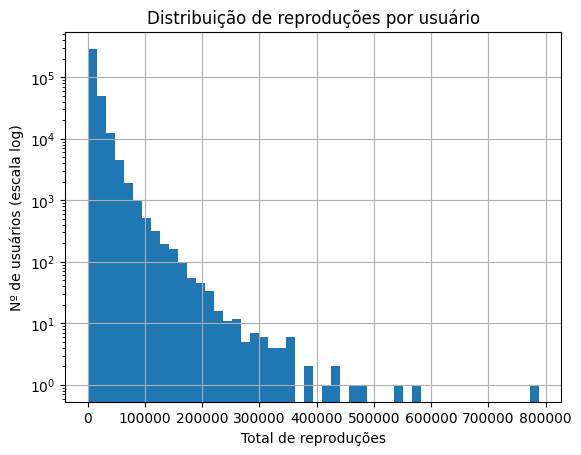

In [8]:
plays_por_usuario = df_plays.groupby("user_id")["plays"].sum()
print(plays_por_usuario.describe())

plays_por_usuario.hist(bins=50, log=True)
plt.xlabel("Total de reproduções")
plt.ylabel("Nº de usuários (escala log)")
plt.title("Distribuição de reproduções por usuário")
plt.show()

## 5. PLAYS — top 20 artistas por total de reproduções

In [9]:
top_artistas = (
    df_plays.groupby("artist_name")["plays"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)
top_artistas

artist_name
the beatles              30499140
radiohead                27452136
coldplay                 16701858
pink floyd               15965959
metallica                15498759
muse                     15463089
nine inch nails          14090643
red hot chili peppers    13562637
linkin park              12848569
system of a down         11927204
in flames                11295957
death cab for cutie      10587605
placebo                   9848924
nightwish                 9765770
the killers               9607866
iron maiden               9509435
bob dylan                 9454759
nirvana                   9284068
depeche mode              9243291
rammstein                 8809758
Name: plays, dtype: int64

## 6. PLAYS — esparsidade da matriz usuário-artista

In [10]:
esparsidade = 1 - len(df_plays) / (n_usuarios * n_artistas)
print(f"Esparsidade da matriz usuário-artista: {esparsidade:.6f}")

Esparsidade da matriz usuário-artista: 0.999833


## 7. PROFILE — visão geral e valores nulos

In [11]:
df_profile.info()
print("\nValores nulos por coluna:")
print(df_profile.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 359347 entries, 0 to 359346
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   user_id      359347 non-null  str    
 1   gender       326572 non-null  str    
 2   age          284447 non-null  float64
 3   country      359347 non-null  str    
 4   signup_date  359347 non-null  str    
dtypes: float64(1), str(4)
memory usage: 35.0 MB

Valores nulos por coluna:
user_id            0
gender         32775
age            74900
country            0
signup_date        0
dtype: int64


## 8. PROFILE — gênero

In [12]:
df_profile["gender"].value_counts(dropna=False)

gender
m      241642
f       84930
NaN     32775
Name: count, dtype: int64

## 9. PROFILE — idade
filtramos antes de plotar, deixando apenas valores 0 < idade < 100

Idade (bruta, sem filtro):
count    284447.000000
mean         25.098046
std          21.665742
min       -1337.000000
25%          20.000000
50%          23.000000
75%          28.000000
max        1002.000000
Name: age, dtype: float64



Idade (0 < idade < 100):
count    283162.000000
mean         25.015023
std           8.040210
min           1.000000
25%          20.000000
50%          23.000000
75%          28.000000
max          99.000000
Name: age, dtype: float64


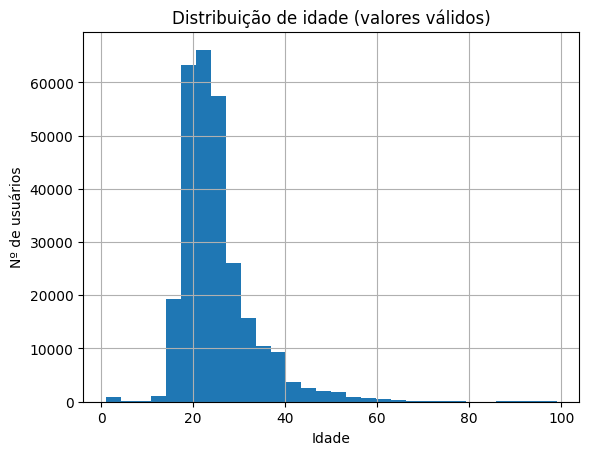

In [13]:
print("Idade (bruta, sem filtro):")
print(df_profile["age"].describe())

idade_valida = df_profile[(df_profile["age"] > 0) & (df_profile["age"] < 100)]["age"]
print("\nIdade (0 < idade < 100):")
print(idade_valida.describe())

idade_valida.hist(bins=30)
plt.xlabel("Idade")
plt.ylabel("Nº de usuários")
plt.title("Distribuição de idade (valores válidos)")
plt.show()

## 10. PROFILE — top 20 países

In [14]:
df_profile["country"].value_counts(dropna=False).head(20)

country
United States         67044
Germany               31651
United Kingdom        29902
Poland                20987
Russian Federation    19833
Brazil                14534
Sweden                13122
Spain                 13051
Finland               11579
Netherlands            9650
Canada                 8679
France                 7529
Italy                  7525
Australia              7135
Japan                  6637
Turkey                 6452
Norway                 5155
Mexico                 4834
Czech Republic         4774
Ukraine                4396
Name: count, dtype: int64

## 11. PROFILE — intervalo de datas de cadastro

In [15]:
df_profile["signup_date_parsed"] = pd.to_datetime(df_profile["signup_date"], errors="coerce")
print(df_profile["signup_date_parsed"].min(), "→", df_profile["signup_date_parsed"].max())

2002-10-29 00:00:00 → 2009-11-11 00:00:00


## 12. Cruzamento — volume de interação × perfil

In [16]:
df_merge = df_profile.merge(
    plays_por_usuario.rename("total_plays"), on="user_id", how="left"
)

print("Total de reproduções (mediana) por país — top 10:")
print(df_merge.groupby("country")["total_plays"].median().sort_values(ascending=False).head(10))

print("\nUsuários no profile sem nenhuma interação em plays:")
print(df_merge["total_plays"].isna().sum())

Total de reproduções (mediana) por país — top 10:
country
Eritrea                     21132.5
Saint Kitts and Nevis       18163.5
Guinea-Bissau               17109.0
Gambia                      16855.0
Turkmenistan                15375.0
Sao Tome and Principe       14432.5
Guyana                      13569.0
Tonga                       12907.5
Lesotho                     12759.0
Turks and Caicos Islands    10988.0
Name: total_plays, dtype: float64

Usuários no profile sem nenhuma interação em plays:
0


## 13. Registros inválidos
Linhas com `plays <= 0` e sem `artist_mbid`. Como uma parcela relevante das linhas não tem MBID, a chave do artista passa a ser o nome normalizado (minúsculas, sem espaços nas pontas).

In [17]:
print("Linhas com plays <= 0:", int((df_plays["plays"] <= 0).sum()))
print(f"Linhas sem artist_mbid: {df_plays['artist_mbid'].isna().sum()} ({df_plays['artist_mbid'].isna().mean():.2%})")
print("Linhas sem artist_name:", int(df_plays["artist_name"].isna().sum()))

Linhas com plays <= 0: 1


Linhas sem artist_mbid: 226452 (1.29%)


Linhas sem artist_name: 202


## 14. Grau dos nós e viés de popularidade
Para o grafo importa o número de arestas (artistas distintos por usuário e ouvintes por artista), não a soma de reproduções. A curva de popularidade quantifica a cauda longa que motiva medir cobertura de catálogo.

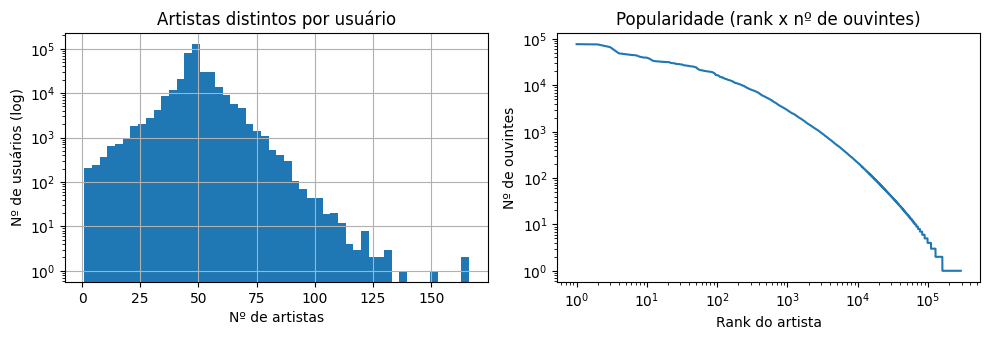

count    359349.000000
mean         48.864076
std           8.522747
min           1.000000
25%          46.000000
50%          49.000000
75%          51.000000
max         166.000000
Name: artist_name, dtype: float64
Top 1% dos artistas concentram 64.7% das interações
Top 5% dos artistas concentram 86.8% das interações
Top 10% dos artistas concentram 92.7% das interações


In [18]:
deg_u = df_plays.groupby("user_id")["artist_name"].nunique()
deg_a = df_plays.groupby("artist_name")["user_id"].nunique().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
deg_u.hist(bins=50, ax=ax[0]); ax[0].set(title="Artistas distintos por usuário", yscale="log",
                                         xlabel="Nº de artistas", ylabel="Nº de usuários (log)")
ax[1].loglog(range(1, len(deg_a) + 1), deg_a.values)
ax[1].set(title="Popularidade (rank x nº de ouvintes)", xlabel="Rank do artista", ylabel="Nº de ouvintes")
plt.tight_layout(); plt.savefig("results/eda_grau_popularidade.png", dpi=200); plt.show()

print(deg_u.describe())
share = deg_a.cumsum() / deg_a.sum()
for p in (0.01, 0.05, 0.10):
    print(f"Top {p:.0%} dos artistas concentram {share.iloc[int(len(deg_a) * p)]:.1%} das interações")

Gênero e idade aparecem aqui apenas de forma descritiva. Eles **não são usados na modelagem**, para reduzir risco de viés e de reidentificação; o único atributo de usuário aproveitado é o país.